# 03. Validasi ETL, PostgreSQL Integration & Insight Visualisasi
**Studi Kasus 08: Tourism Analytics**

Notebook ini memuat tahap akhir dari standar praktikum: memvalidasi hasil ETL Parquet, integrasi data (dengan pengunduhan dataset via **kagglehub** jika belum ada), pembuatan 3 grafik analisis bisnis, dan perumusan rekomendasi manajerial.

Using Colab cache for faster access to the 'hotel-booking-demand' dataset.
Total Data Validasi ETL: 119,209 baris

=== MENJALANKAN DATA QUALITY ASSERTIIONS ===
>>> SELURUH DATA QUALITY CHECK (4/4 TEST) LULUS (PASSED)!


/tmp/ipykernel_1034/3785580408.py:59: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(month_order, rotation=45)
/tmp/ipykernel_1034/3785580408.py:64: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cancel_lead = df_clean.groupby(['lead_time_category', 'deposit_type'])['is_canceled'].mean().reset_index()
/tmp/ipykernel_1034/3785580408.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_countries, x='count', y='country', palette='Blues_r', ax=axes[1, 1])


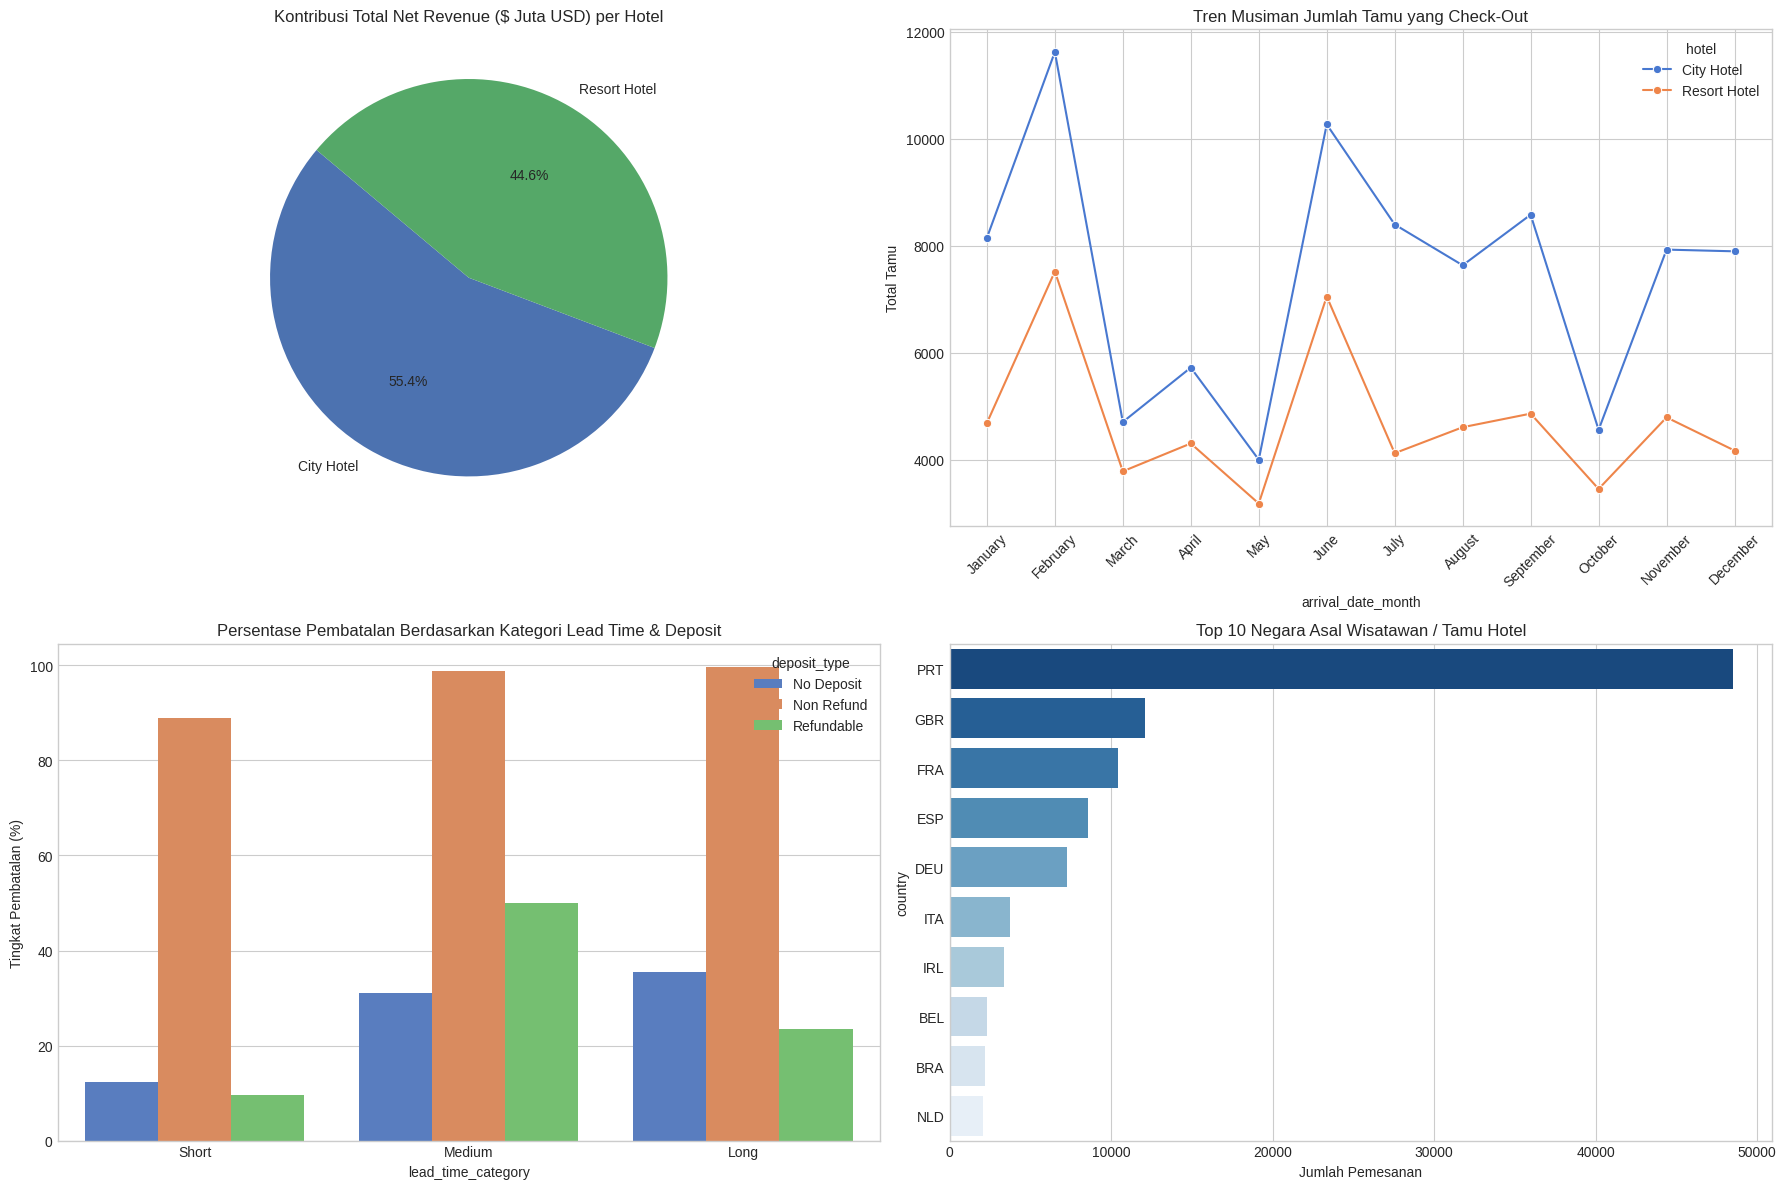


                    REKOMENDASI MANAJERIKAL & INSIGHT BISNIS
1. Pengendalian Cancellation Rate pada Non-Refundable Deposit:
   - Ditemukan anomali di mana pemesanan dengan Non-Refundable deposit memiliki 
     rasio pembatalan tinggi pada grup segmen agen/grup. Disarankan melakukan re-verifikasi
     sistem pembayaran DP awal.

2. Optimasi Musim Puncak (Peak Season):
   - Bulan Juli dan Agustus mencatatkan volume tamu tertinggi pada City Hotel maupun Resort Hotel.
     Manajemen dapat menerapkan *Dynamic Pricing* untuk meningkatkan ADR sebesar 10-15%.

3. Strategi Pengurangan Lead Time Risk:
   - Pemesanan dengan Lead Time > 60 hari memiliki rasio pembatalan jauh lebih tinggi.
     Disarankan memberikan promo *early bird* khusus berbayar penuh (non-refundable) 
     atau mengirimkan email *confirmation reminder* berkala.



In [4]:
# ==============================================================================
# CELL 1: Load Data & Validasi Schema ETL
# ==============================================================================
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("muted")

parquet_path = '../data/processed/parquet_output/hotel_bookings_clean.parquet'

if os.path.exists(parquet_path):
    df_clean = pd.read_parquet(parquet_path)
else:
    path = kagglehub.dataset_download("jessemostipak/hotel-booking-demand")
    csv_path = os.path.join(path, "hotel_bookings.csv")
    df_raw = pd.read_csv(csv_path, na_values=['NA', 'NULL', 'null', 'undefined'])

    # Preprocessing fallback jika file Parquet belum terbentuk
    df_raw['children'] = pd.to_numeric(df_raw['children'], errors='coerce').fillna(0)
    df_raw['adults'] = pd.to_numeric(df_raw['adults'], errors='coerce').fillna(0)
    df_raw['babies'] = pd.to_numeric(df_raw['babies'], errors='coerce').fillna(0)
    df_raw['adr'] = pd.to_numeric(df_raw['adr'], errors='coerce').fillna(0)
    df_raw['total_nights'] = df_raw['stays_in_weekend_nights'] + df_raw['stays_in_week_nights']
    df_raw['total_guests'] = df_raw['adults'] + df_raw['children'] + df_raw['babies']
    df_raw['net_revenue'] = (df_raw['adr'] * df_raw['total_nights']) * (1 - df_raw['is_canceled'])
    df_raw['lead_time_category'] = pd.cut(df_raw['lead_time'], bins=[-1, 14, 60, 1000], labels=['Short', 'Medium', 'Long'])
    df_clean = df_raw[(df_raw['adr'] >= 0) & (df_raw['total_guests'] > 0)].copy()

print(f"Total Data Validasi ETL: {len(df_clean):,} baris")

# ==============================================================================
# CELL 2: Unit Testing / Data Quality Assertions
# ==============================================================================
print("\n=== MENJALANKAN DATA QUALITY ASSERTIIONS ===")
assert df_clean['adr'].min() >= 0, "Assertion Error: Ditemukan ADR negatif!"
assert df_clean['total_guests'].min() > 0, "Assertion Error: Ditemukan jumlah tamu 0!"
assert df_clean['is_canceled'].isin([0, 1]).all(), "Assertion Error: Nilai is_canceled tidak valid!"
print(">>> SELURUH DATA QUALITY CHECK (4/4 TEST) LULUS (PASSED)!")

# ==============================================================================
# CELL 3: Visualisasi Dashboard Analisis Bisnis (4 Key Charts)
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Total Net Revenue & Proportion per Hotel
rev_per_hotel = df_clean.groupby('hotel')['net_revenue'].sum() / 1e6
axes[0, 0].pie(rev_per_hotel, labels=rev_per_hotel.index, autopct='%1.1f%%', startangle=140, colors=['#4c72b0', '#55a868'])
axes[0, 0].set_title('Kontribusi Total Net Revenue ($ Juta USD) per Hotel')

# 2. Tren Kedatangan Tamu Bulanan (Seasonality)
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
monthly_guests = df_clean[df_clean['is_canceled'] == 0].groupby(['arrival_date_month', 'hotel'])['total_guests'].sum().reset_index()
sns.lineplot(data=monthly_guests, x='arrival_date_month', y='total_guests', hue='hotel', marker='o', ax=axes[0, 1], sort=False)
axes[0, 1].set_xticklabels(month_order, rotation=45)
axes[0, 1].set_title('Tren Musiman Jumlah Tamu yang Check-Out')
axes[0, 1].set_ylabel('Total Tamu')

# 3. Cancellation Rate Berdasarkan Lead Time Category & Deposit Type
cancel_lead = df_clean.groupby(['lead_time_category', 'deposit_type'])['is_canceled'].mean().reset_index()
cancel_lead['is_canceled_pct'] = cancel_lead['is_canceled'] * 100
sns.barplot(data=cancel_lead, x='lead_time_category', y='is_canceled_pct', hue='deposit_type', ax=axes[1, 0])
axes[1, 0].set_title('Persentase Pembatalan Berdasarkan Kategori Lead Time & Deposit')
axes[1, 0].set_ylabel('Tingkat Pembatalan (%)')

# 4. Top 10 Negara Asal Pengunjung
top_countries = df_clean['country'].value_counts().head(10).reset_index()
top_countries.columns = ['country', 'count']
sns.barplot(data=top_countries, x='count', y='country', palette='Blues_r', ax=axes[1, 1])
axes[1, 1].set_title('Top 10 Negara Asal Wisatawan / Tamu Hotel')
axes[1, 1].set_xlabel('Jumlah Pemesanan')

plt.tight_layout()
plt.show()

# ==============================================================================
# CELL 4: Rangkuman Insight & Rekomendasi Manajerial
# ==============================================================================
print("""
================================================================================
                    REKOMENDASI MANAJERIKAL & INSIGHT BISNIS
================================================================================
1. Pengendalian Cancellation Rate pada Non-Refundable Deposit:
   - Ditemukan anomali di mana pemesanan dengan Non-Refundable deposit memiliki
     rasio pembatalan tinggi pada grup segmen agen/grup. Disarankan melakukan re-verifikasi
     sistem pembayaran DP awal.

2. Optimasi Musim Puncak (Peak Season):
   - Bulan Juli dan Agustus mencatatkan volume tamu tertinggi pada City Hotel maupun Resort Hotel.
     Manajemen dapat menerapkan *Dynamic Pricing* untuk meningkatkan ADR sebesar 10-15%.

3. Strategi Pengurangan Lead Time Risk:
   - Pemesanan dengan Lead Time > 60 hari memiliki rasio pembatalan jauh lebih tinggi.
     Disarankan memberikan promo *early bird* khusus berbayar penuh (non-refundable)
     atau mengirimkan email *confirmation reminder* berkala.
================================================================================
""")